# Phase G: usage profiles
Scratch work for section 8. Training/CV seasons only; final regression remains frozen.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

# Same values as the main notebook's config cell. Change them there, not here.
SEED = 363
POSITIONS = ["QB", "RB", "WR", "TE"]
TRAIN_SEASONS = list(range(2020, 2025))
TEST_SEASON = 2025
TARGET = "fantasy_points_ppr"
CV_VALID_SEASONS = [2022, 2023, 2024]
TOP_N = 12

## Shared data
`features` has one row per player-week (2020-2025) with the target. `FEATURE_FAMILIES` lists the only columns that may be used as model inputs. `train` drops 2025, which is only for the final test (Phase H).

In [2]:
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
FEATURE_FAMILIES = json.loads((PROCESSED_DIR / "feature_families.json").read_text())
ALL_FEATURES = [c for cols in FEATURE_FAMILIES.values() for c in cols]

train = features[features["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
print(f"train: {train.shape}, features: {len(ALL_FEATURES)}")

train: (18402, 55), features: 48


## Shared evaluation (copied exactly from main notebook section 5.6; a test checks they match)

In [3]:
def cv_folds(data):
    for season in CV_VALID_SEASONS:
        train = data.index[data["season"].between(TRAIN_SEASONS[0], season - 1)]
        valid = data.index[data["season"] == season]
        yield season, train, valid


def top_n_hit_rate(week):
    predicted_top = set(week.nlargest(TOP_N, "pred").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return len(predicted_top & actual_top) / TOP_N


def evaluate(data, pred):
    d = data.assign(pred=np.asarray(pred))
    groups = d.groupby(["season", "week", "position"])
    return {
        "rmse": float(np.sqrt(((d["pred"] - d[TARGET]) ** 2).mean())),
        "mae": float((d["pred"] - d[TARGET]).abs().mean()),
        "spearman": float(groups.apply(lambda w: w["pred"].corr(w[TARGET], method="spearman")).mean()),
        "top12_hit_rate": float(groups.apply(top_n_hit_rate).mean()),
    }


def cross_validate(model, data, columns):
    """Fit on each expanding-window fold; return mean metrics and the out-of-fold predictions."""
    from sklearn.base import clone
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        fitted = clone(model).fit(data.loc[train, columns], data.loc[train, TARGET])
        preds.loc[valid] = fitted.predict(data.loc[valid, columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds

In [4]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import nflreadpy as nfl
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import itertools
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import (AdaBoostRegressor, BaggingRegressor, HistGradientBoostingRegressor,
                              StackingRegressor, VotingRegressor)
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
def scaled(*steps):
    return make_pipeline(StandardScaler(), *steps)
def make_lasso(**params):
    return Lasso(max_iter=5000, **params)
def make_boosting(**params):
    return HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params)
def make_mlp(**params):
    return MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED, **params)
def vote_members(params):
    return [("lasso", make_lasso(**params["Lasso"])),
            ("boosting", make_boosting(**params["Gradient boosting"])),
            ("mlp", make_mlp(**params["MLP"]))]
def make_vote(params):
    return scaled(VotingRegressor(vote_members(params)))
def age_weights(rows, season, week, half_life):
    "Training weight per game: halves every `half_life` seasons before the week being predicted."
    if half_life is None:
        return None
    age_in_seasons = (season - rows["season"]) + (week - rows["week"]) / WEEKS_PER_SEASON
    return (0.5 ** (age_in_seasons / half_life)).to_numpy()
def fit_weighted(model, rows, columns, weights=None):
    "Fit a fresh copy of a pipeline, passing sample weights to its last step when given."
    fitted = clone(model)
    if weights is None:
        return fitted.fit(rows[columns], rows[TARGET])
    return fitted.fit(rows[columns], rows[TARGET], **{f"{fitted.steps[-1][0]}__sample_weight": weights})
def cross_validate_recency(model, data, columns, window=None, half_life=None, refit_weekly=False):
    "cross_validate() with a training window (seasons), age weights (half-life in seasons), and weekly refits."
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        earlier = data.loc[train]
        if window is not None:
            earlier = earlier[earlier["season"] >= season - window]
        this_season = data.loc[valid]
        weeks = sorted(this_season["week"].unique()) if refit_weekly else [this_season["week"].min()]
        for week in weeks:
            rows = pd.concat([earlier, this_season[this_season["week"] < week]])
            fitted = fit_weighted(model, rows, columns, age_weights(rows, season, week, half_life))
            target = this_season[this_season["week"] == week] if refit_weekly else this_season
            preds.loc[target.index] = fitted.predict(target[columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds
import json
def make_regression_model(choice):
    return make_vote(choice["params"])

In [5]:
from IPython.display import Markdown
import matplotlib.pyplot as plt
import seaborn as sns
KEY = ['gsis_id','season','week']
WEEKS_PER_SEASON = 18
G_OUTPUT_DIR = ROOT / 'data/scratch/G'
VOTE_MEMBERS = ['Lasso','Gradient boosting','MLP']

### 8.1 Compare usage profiles
This extension uses only 2020-2024. The candidate settings and selection rule below are fixed before the comparison: compare standardized K-Means, Ward hierarchical clustering, and DBSCAN on the same 2020-2021 sample. Select K-Means k by silhouette among its candidates; K-Means supports assignment of future players without refitting on them. Other methods are descriptive comparisons. No points or expert ranks enter clustering.

,clusters,coverage,silhouette,davies_bouldin
method,,,,
K-Means k=3,3,1.000,0.396,0.955
K-Means k=4,4,1.000,0.480,0.732
K-Means k=5,5,1.000,0.398,0.870
K-Means k=6,6,1.000,0.379,0.968
Ward k=3,3,1.000,0.481,0.808
Ward k=4,4,1.000,0.433,0.797
Ward k=5,5,1.000,0.369,0.885
Ward k=6,6,1.000,0.359,0.962
DBSCAN eps=0.5,2,0.228,0.823,0.252


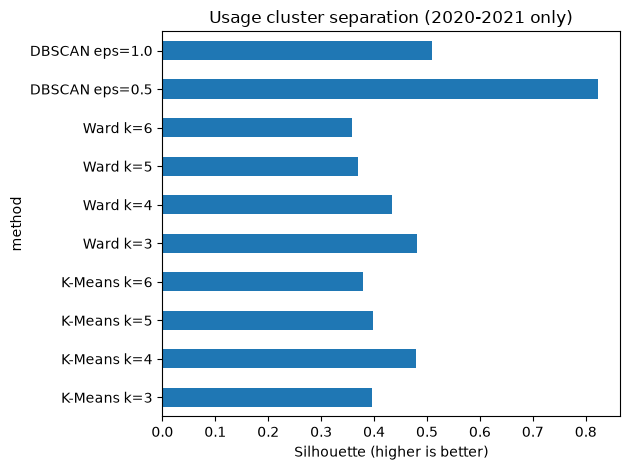

**What we see:** K-Means k=4 has the best K-Means silhouette (0.480). DBSCAN coverage is shown because excluding noise can inflate its score. These are role groups, not predicted scoring tiers.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

G_OUTPUT_DIR = globals().get('G_OUTPUT_DIR', PROCESSED_DIR)
G_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
G_CONFIG = {'k_candidates': [3, 4, 5, 6], 'sample_size': 2500, 'dbscan_eps': [0.5, 1.0], 'min_samples': 20}
g_columns = [c for c in FEATURE_FAMILIES['usage'] if c.endswith(('_last3', '_recent'))]
g_rows = features[features.season.isin(TRAIN_SEASONS)].sort_values(KEY).reset_index(drop=True)
assert g_rows.season.max() < TEST_SEASON
assert g_columns and not any('ecr' in c or 'points' in c for c in g_columns)
g_initial = g_rows[g_rows.season < CV_VALID_SEASONS[0]]
g_scaler = StandardScaler().fit(g_initial[g_columns])
g_sample = g_initial.sample(min(G_CONFIG['sample_size'], len(g_initial)), random_state=SEED)
g_x = g_scaler.transform(g_sample[g_columns])
g_candidates = {f'K-Means k={k}':KMeans(n_clusters=k, n_init=10, random_state=SEED) for k in G_CONFIG['k_candidates']}
g_candidates.update({f'Ward k={k}':AgglomerativeClustering(n_clusters=k) for k in G_CONFIG['k_candidates']})
g_candidates.update({f'DBSCAN eps={eps}':DBSCAN(eps=eps,min_samples=G_CONFIG['min_samples']) for eps in G_CONFIG['dbscan_eps']})
g_comparison_rows = []
for name, model in g_candidates.items():
    labels = model.fit_predict(g_x)
    keep = labels != -1
    n_groups = len(set(labels[keep]))
    valid = 1 < n_groups < keep.sum()
    g_comparison_rows.append({'method':name, 'clusters':n_groups, 'coverage':keep.mean(),
        'silhouette':silhouette_score(g_x[keep],labels[keep]) if valid else np.nan,
        'davies_bouldin':davies_bouldin_score(g_x[keep],labels[keep]) if valid else np.nan})
g_comparison = pd.DataFrame(g_comparison_rows).set_index('method')
g_best_name = g_comparison.loc[g_comparison.index.str.startswith('K-Means'), 'silhouette'].idxmax()
g_k = int(g_best_name.split('=')[1])
display(g_comparison.round(3))
g_comparison.silhouette.plot.barh(title='Usage cluster separation (2020-2021 only)',xlabel='Silhouette (higher is better)')
plt.tight_layout(); plt.show()
display(Markdown(f"**What we see:** {g_best_name} has the best K-Means silhouette ({g_comparison.loc[g_best_name,'silhouette']:.3f}). DBSCAN coverage is shown because excluding noise can inflate its score. These are role groups, not predicted scoring tiers."))

### 8.2 Describe profiles and movement
A fixed 2020-2021 fit supplies stable label IDs for descriptive exports. Later seasons are assigned to those same centroids. A switch compares a player to their previous row in the modeling pool, across byes and seasons; it is not necessarily a switch since the previous NFL game. First observations are not switches. Cluster IDs are nominal.

,snap_share_last3,snap_share_recent,target_share_last3,target_share_recent,carry_share_last3,carry_share_recent,air_yards_share_last3,air_yards_share_recent,opportunities_last3,opportunities_recent
cluster,,,,,,,,,,
0,0.938,0.920,0.001,0.001,0.138,0.136,0.000,0.000,35.890,35.355
1,0.805,0.782,0.216,0.207,0.007,0.007,0.277,0.265,7.222,6.992
2,0.600,0.557,0.104,0.099,0.520,0.483,-0.002,-0.001,17.428,16.243
3,0.570,0.522,0.092,0.088,0.013,0.012,0.091,0.090,3.726,3.582


position,QB,RB,WR,TE
row_0,,,,
0,2647,0,0,0
1,0,0,5026,1090
2,13,2876,0,1
3,169,417,3097,3066


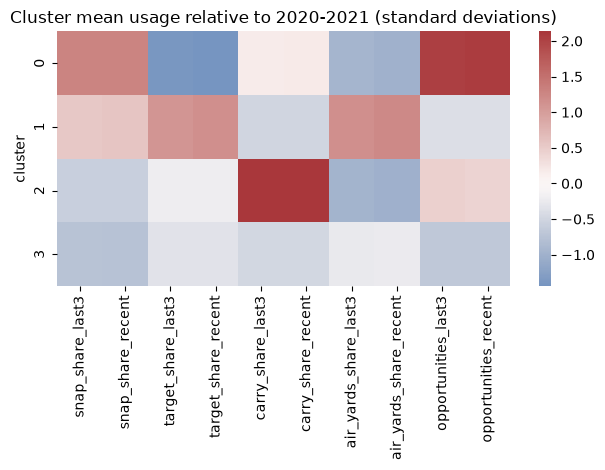

**What we see:**
- Cluster 0: mostly QB; snap_share 0.94, target_share 0.00, carry_share 0.14, air_yards_share 0.00, opportunities 35.89.
- Cluster 1: mostly WR; snap_share 0.80, target_share 0.22, carry_share 0.01, air_yards_share 0.28, opportunities 7.22.
- Cluster 2: mostly RB; snap_share 0.60, target_share 0.10, carry_share 0.52, air_yards_share -0.00, opportunities 17.43.
- Cluster 3: mostly WR; snap_share 0.57, target_share 0.09, carry_share 0.01, air_yards_share 0.09, opportunities 3.73.

Players switch on 5.7% of 17,645 transitions. Overlapping rolling windows make consecutive profiles similar. Labels for 2020-2021 are descriptive in-sample assignments; later labels are out of sample. No 2025 labels are exported.

In [7]:
g_profile = make_pipeline(StandardScaler(), KMeans(n_clusters=g_k,n_init=10,random_state=SEED))
g_profile.fit(g_initial[g_columns])
g_labels = pd.Series(g_profile.predict(g_rows[g_columns]),index=g_rows.index)
g_previous = g_labels.groupby(g_rows.gsis_id).shift(1)
g_switched = g_previous.notna() & g_labels.ne(g_previous)
usage_clusters = g_rows[KEY].assign(cluster=g_labels,switched_cluster=g_switched)
usage_clusters.to_parquet(G_OUTPUT_DIR / 'usage_clusters.parquet',index=False)
g_profiles = g_rows[g_columns].assign(cluster=g_labels).groupby('cluster').mean()
g_counts = pd.crosstab(g_labels,g_rows.position).reindex(columns=POSITIONS,fill_value=0)
display(g_profiles.round(3)); display(g_counts)
sns.heatmap(pd.DataFrame(g_scaler.transform(g_profiles),index=g_profiles.index,columns=g_columns),cmap='vlag',center=0)
plt.title('Cluster mean usage relative to 2020-2021 (standard deviations)'); plt.tight_layout(); plt.show()
g_role_names=[]
for cluster, row in g_profiles.iterrows():
    top_position = g_counts.loc[cluster].idxmax()
    leaders = row[[c for c in g_columns if c.endswith('_last3')]].sort_values(ascending=False)
    # Shares and opportunities have different units, so report them rather than comparing magnitudes.
    text = ', '.join(f"{c.removesuffix('_last3')} {v:.2f}" for c,v in row.items() if c.endswith('_last3'))
    g_role_names.append(f"- Cluster {cluster}: mostly {top_position}; {text}.")
g_switch_rate = g_switched[g_previous.notna()].mean()
display(Markdown('**What we see:**\n' + '\n'.join(g_role_names) + f"\n\nPlayers switch on {g_switch_rate:.1%} of {g_previous.notna().sum():,} transitions. Overlapping rolling windows make consecutive profiles similar. Labels for 2020-2021 are descriptive in-sample assignments; later labels are out of sample. No 2025 labels are exported."))

### 8.3 Do profiles add predictive value?
Fit scaling and centroids inside each regression training fold or week. Encode the labels as one-hot columns, plus a switch flag computed by assigning both the current and previous usage vectors under the same fitted centroids. This avoids comparing arbitrary labels across refits. The original pre-game features remain in the regression.

Use the shared CV functions and the frozen regression factory. First compare annual refits, then compare the chosen weekly cadence to E's saved predictions on identical rows. This is an exploratory CV comparison after H was frozen; it cannot change the final model or its 2025 verdict.

In [8]:
g_previous_columns = [f'g_previous_{c}' for c in g_columns]
g_rows[g_previous_columns] = g_rows.groupby('gsis_id')[g_columns].shift(1).to_numpy()
g_rows['g_has_previous'] = g_previous.notna().astype(int)
g_rows[g_previous_columns] = g_rows[g_previous_columns].fillna(g_rows[g_columns].rename(columns=dict(zip(g_columns,g_previous_columns))))
g_input_columns = ALL_FEATURES + g_previous_columns + ['g_has_previous']

class UsageProfiles(BaseEstimator, TransformerMixin):
    def __init__(self, usage_columns, base_columns, n_clusters, seed):
        self.usage_columns = usage_columns
        self.base_columns = base_columns
        self.n_clusters = n_clusters
        self.seed = seed

    def fit(self, X, y=None):
        self.profiles_ = make_pipeline(StandardScaler(), KMeans(n_clusters=self.n_clusters,n_init=10,random_state=self.seed))
        self.profiles_.fit(X[self.usage_columns])
        return self

    def transform(self, X):
        labels = self.profiles_.predict(X[self.usage_columns])
        prior = X[[f'g_previous_{c}' for c in self.usage_columns]].copy()
        prior.columns = self.usage_columns
        prior_labels = self.profiles_.predict(prior)
        changed = (labels != prior_labels) & X['g_has_previous'].to_numpy().astype(bool)
        return np.column_stack([X[self.base_columns], np.eye(self.n_clusters)[labels], changed.astype(int)])

g_choice = json.loads((PROCESSED_DIR / 'regression_choice.json').read_text())
assert g_choice['status'] == 'final' and g_choice['refit'] == 'every week'
g_model = make_pipeline(UsageProfiles(g_columns, ALL_FEATURES, g_k, SEED),make_regression_model(g_choice))
g_plain_annual, _ = cross_validate(make_regression_model(g_choice),g_rows,ALL_FEATURES)
g_cluster_annual, _ = cross_validate(g_model,g_rows,g_input_columns)
g_cluster_weekly, g_oof = cross_validate_recency(g_model,g_rows,g_input_columns,refit_weekly=True)
g_saved = pd.read_parquet(PROCESSED_DIR / 'preds_regression.parquet')
g_match = g_rows.merge(g_saved[KEY+['pred']],on=KEY,validate='one_to_one')
g_plain_weekly = evaluate(g_match,g_match.pred)
g_results = pd.DataFrame({'annual: original':g_plain_annual,'annual: clusters + switch':g_cluster_annual,
                          'weekly: original':g_plain_weekly,'weekly: clusters + switch':g_cluster_weekly}).T
display(g_results.round(4))
g_scored = g_oof.notna()
g_predictions = g_rows.loc[g_scored,KEY+['position',TARGET]].assign(pred=g_oof[g_scored])
g_predictions.to_parquet(G_OUTPUT_DIR / 'usage_cluster_cv_predictions.parquet',index=False)
g_results.to_csv(G_OUTPUT_DIR / 'usage_cluster_comparison.csv')
(G_OUTPUT_DIR / 'usage_cluster_choice.json').write_text(json.dumps({'k':g_k,'usage_columns':g_columns,
 'selection_seasons':[2020,2021],'evaluation_seasons':CV_VALID_SEASONS,'export_seasons':TRAIN_SEASONS,
 'selection_rule':'best K-Means silhouette on initial training sample','changes_frozen_regression':False},indent=2))
g_delta = g_cluster_weekly['spearman'] - g_plain_weekly['spearman']
display(Markdown(f"**What we see:** clusters change weekly-refit CV Spearman by {g_delta:+.4f} and RMSE by {g_cluster_weekly['rmse']-g_plain_weekly['rmse']:+.4f}. {'The ranking gain is positive in this CV comparison.' if g_delta > 0 else 'The profiles do not improve ranking in this CV comparison.'} The profiles are derived from existing inputs, so they add a representation, not new information. The frozen regression and 2025 predictions are unchanged."))

,rmse,mae,spearman,top12_hit_rate
annual: original,6.7651,5.1705,0.5247,0.4900
annual: clusters + switch,6.7710,5.1804,0.5231,0.4911
weekly: original,6.7658,5.1766,0.5251,0.4888
weekly: clusters + switch,6.7664,5.1805,0.5254,0.4892


**What we see:** clusters change weekly-refit CV Spearman by +0.0003 and RMSE by +0.0006. The ranking gain is positive in this CV comparison. The profiles are derived from existing inputs, so they add a representation, not new information. The frozen regression and 2025 predictions are unchanged.